# Chapter 11 : Implementing a Multilayer Artificial Neural Network from Scratch

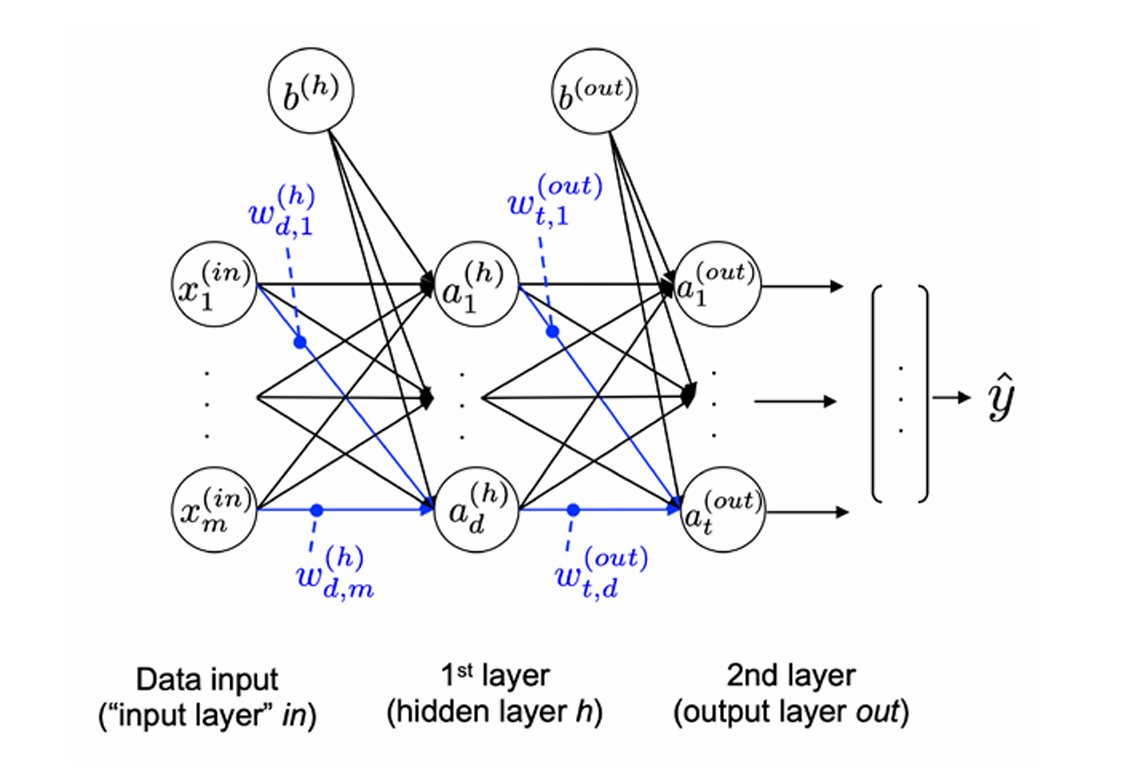

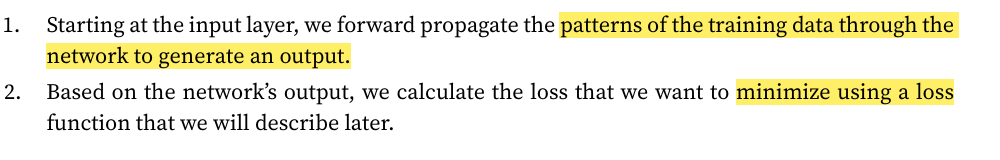
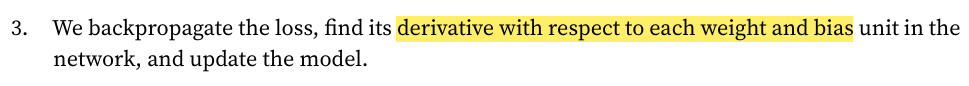

### Looking deeper at each step 

- Firstly each input is connected to the hidden layer so we can take this caluclation and pass it through our activation function. 

- 
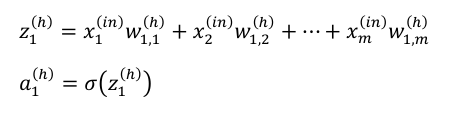


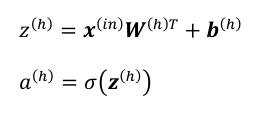


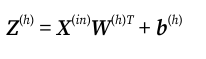

###  Classifying handwritten digits

In [3]:
from sklearn.datasets import fetch_openml 

X, y = fetch_openml('mnist_784', version = 1 , return_X_y = True)

X   = X.values 
y = y.astype('int').values

print(X.shape , y.shape )

(70000, 784) (70000,)


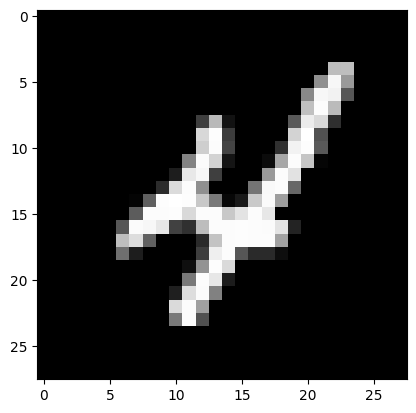

In [4]:
import matplotlib.pyplot as plt 

plt.imshow((X[9].reshape(28,28)), cmap='gray', vmin=0, vmax=255)

In [3]:
X = ((X / 255.) - .5) * 2


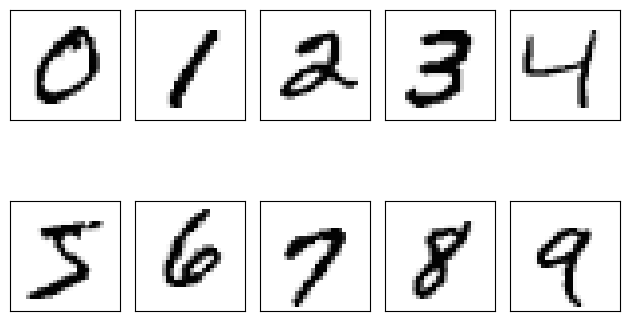

In [5]:
fig, ax = plt.subplots(nrows=2, ncols=5,
                        sharex=True, sharey=True)
ax = ax.flatten()
for i in range(10):

        img = X[y == i][0].reshape(28, 28)
        ax[i].imshow(img, cmap='Greys')
        
ax[0].set_xticks([])
ax[0].set_yticks([])
plt.tight_layout()
plt.show()

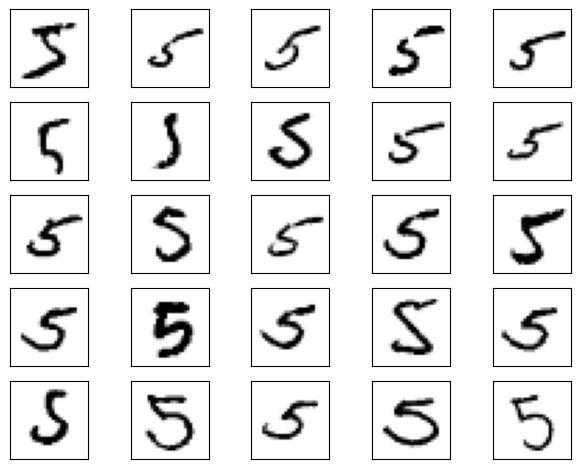

In [5]:
fig, ax = plt.subplots(nrows=5,
 
                        ncols=5,
                        sharex=True,
                        sharey=True)
ax = ax.flatten()

for i in range(25):
     img = X[y == 5][i].reshape(28, 28)
     ax[i].imshow(img, cmap='Greys')
ax[0].set_xticks([])
ax[0].set_yticks([])
plt.tight_layout()
plt.show()

In [6]:
from sklearn.model_selection import train_test_split


X_temp, X_test, y_temp, y_test = train_test_split(
X, y, test_size=10000, random_state=123, stratify=y
 )
X_train, X_valid, y_train, y_valid = train_test_split(

X_temp, y_temp, test_size=5000,
)

### Implementing a multilayer perceptron

In [7]:
import numpy as np 

def sigmoid(z): 
    return 1 / (1 + np.exp(-z))


def int_to_onehot(y , num_labels): 

    ary = np.zeros((y.shape[0] , num_labels))
    for i,val in enumerate(y): 
        ary[i,val] = 1  #### 

    return ary 



-    The __init__ constructor instantiates the weight matrices and bias vectors for the hidden and the 
    output layer. Next, let’s see how these are used in the forward method to make predictions


-   The forward method takes in one or more training examples and returns the predictions. In fact, it 
    returns both the activation values from the hidden layer and the output layer, a_h and a_out

-   The backward method implements the so-called backpropagation algorithm, which calculates the gra
    dients of the loss with respect to the weight and bias parameters. Similar to Adaline, these gradients 
    are then used to update these parameters via gradient descent.

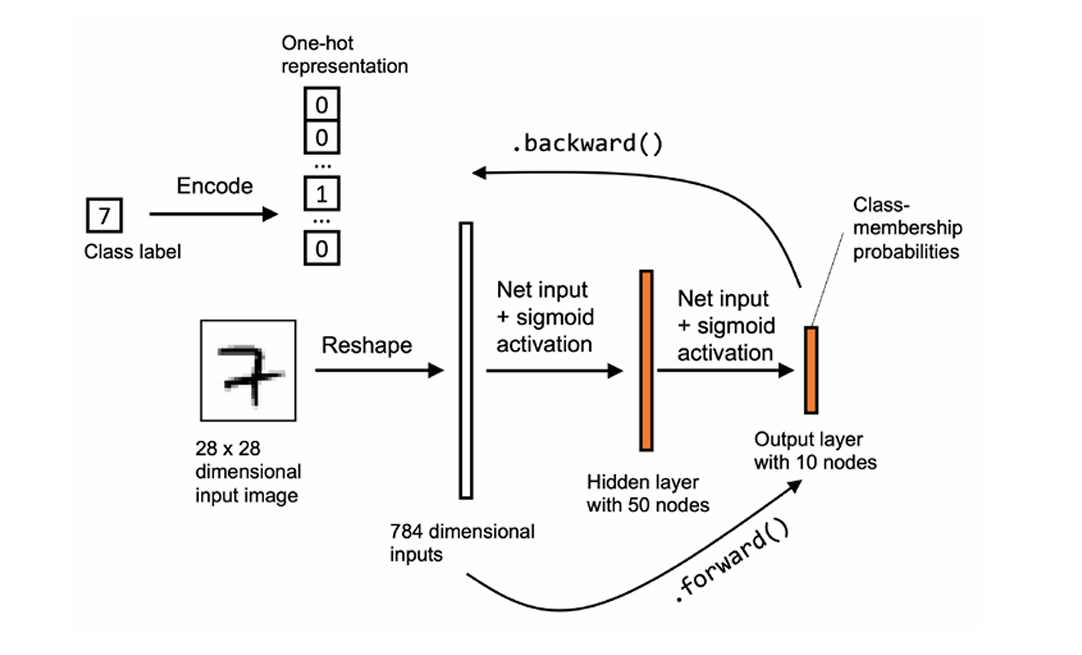

In [8]:
class NeuralNetMLp: 

    def __init__(self , num_features , num_hidden , num_classes , random_seed = 123):
        super().__init__()

        self.num_classes = num_classes

        rng = np.random.RandomState(random_seed)

        self.weight_h = rng.normal(loc=0.0 , scale=0.1,size=(num_hidden, num_features))

        self.bias_h = np.zeros(num_hidden) 

        self.weight_out = rng.normal(loc = 0.0 , scale=0.1 ,size=(num_classes , num_hidden))

        self.bias_out = np.zeros(num_classes)


    def forward(self , x): 

        z_h = np.dot(x,self.weight_h.T) + self.bias_h
        a_h = sigmoid(z_h)

        z_out = np.dot(a_h , self.weight_out.T) + self.bias_out
        a_out = sigmoid(z_out)

        return a_h , a_out
    

    def backward(self , x , a_h , a_out , y): 

        y_onehot = int_to_onehot(y, self.num_classes)

        d_loss_d_a_out = 2. * (a_out - y_onehot)/y.shape[0]

        d_a_out_d_z_out = a_out * (1. - a_out)

        delta_out = d_loss_d_a_out * d_a_out_d_z_out

        d_z_out_dw_out = a_h

        d_loss__dw_out = np.dot(delta_out.T, d_z_out_dw_out)
        
        d_loss__db_out = np.sum(delta_out, axis=0)

        d_z_out_a_h = self.weight_out

        d_z_out__a_h = self.weight_out
        
        # output dim: [n_examples, n_hidden]
        d_loss__a_h = np.dot(delta_out, d_z_out__a_h)
        
        # [n_examples, n_hidden]
        d_a_h__d_z_h = a_h * (1. - a_h) # sigmoid derivative
        
        # [n_examples, n_features]
        d_z_h__d_w_h = x
        
        # output dim: [n_hidden, n_features]
        d_loss__d_w_h = np.dot((d_loss__a_h * d_a_h__d_z_h).T,
                                d_z_h__d_w_h)
        d_loss__d_b_h = np.sum((d_loss__a_h * d_a_h__d_z_h), axis=0)
        return (d_loss__dw_out, d_loss__db_out,
                d_loss__d_w_h, d_loss__d_b_h)

        





In [9]:
model = NeuralNetMLp(num_features=28*28 ,
                     num_hidden=50,
                     num_classes=10)

### Coding the neural network training loop

### Minibatch fuction


In [23]:
num_epochs = 50 
mini_batch_size = 100 

def mini_batch_generator(X,y,minibatch_size):
    indices = np.arange(X.shape[0])
    np.random.shuffle(indices)
    for start_idx in range(0,indices.shape[0] - mini_batch_size + 1 , mini_batch_size):
        batch_idx = indices[start_idx:start_idx+mini_batch_size]
        yield X[batch_idx] ,  y[batch_idx]

In [15]:
# check the mini_batch generator 

for i in range(num_epochs): 
    mini_batch_gen = mini_batch_generator(X_train , y_train, mini_batch_size)
    for X_train_mini , y_train_mini in mini_batch_gen: 
        break 
    break 
print(X_train_mini.shape)
print(y_train_mini.shape)

(100, 784)
(100,)


In [18]:
def mse_loss(targets , probas , num_labels=10): 
    onehot_targets = int_to_onehot(targets , num_labels=num_labels)

    return np.mean((onehot_targets - probas)**2)

def accuracy(targets , predicted_labels): 
    return np.mean(predicted_labels == targets)




In [22]:
_,probas = model.forward(X_valid)
mse = mse_loss(y_valid , probas)

print(f"Initlal Validation MSE:{mse:.1f}")


predicted_labels = np.argmax(probas , axis=1)

acc = accuracy(y_valid , predicted_labels)
print(f"Initial validation accuracy: {acc*100:.1f}%")



Initlal Validation MSE:0.2
Initial validation accuracy: 11.6%


C:\Users\muham\AppData\Local\Temp\ipykernel_12168\3184362591.py:4: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-z))


In [29]:
def compute_mse_and_acc(nnet , X , y , num_labels=10,mini_batch_size=100):

    mse , correct_pred , num_examples = 0. , 0 , 0 
    mini_batch_gen = mini_batch_generator(X, y, mini_batch_size)

    for i , (features , targets) in enumerate(mini_batch_gen): 

        _,probas = nnet.forward(features)
        predicted_labels = np.argmax(probas , axis=1) 
        onehot_targets = int_to_onehot(targets , num_labels=num_labels)

        loss = np.mean((onehot_targets - probas)**2)
        correct_pred += (predicted_labels == targets).sum()
        num_examples += targets.shape[0]
        mse += loss

    mse = mse/i
    acc = correct_pred/num_examples

    return mse , acc 

In [32]:
mse, acc = compute_mse_and_acc(model, X_valid, y_valid)
print(f'Initial valid MSE: {mse:.1f}')
print(f'Initial valid accuracy: {acc*100:.1f}%')

Initial valid MSE: 0.2
Initial valid accuracy: 11.6%


C:\Users\muham\AppData\Local\Temp\ipykernel_12168\3184362591.py:4: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-z))


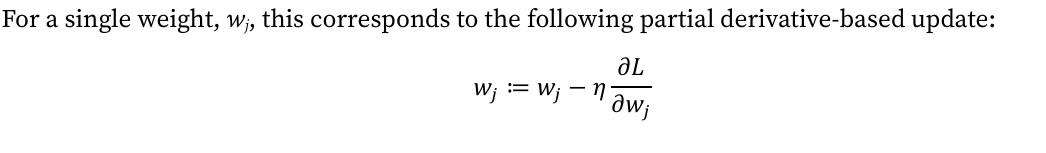

In [41]:
def train(model , X_train , y_train , X_valid , y_valid , num_epochs = 10 , learning_rate=0.1): 

        epoch_loss = []

        epoch_train_acc = []

        epoch_valid_acc = []

        for e in range(num_epochs): 

                mini_batch_gen = mini_batch_generator(X_train , y_train , mini_batch_size)

                for X_train_mini , y_train_mini in mini_batch_gen: 

                    # computing the output 
                    a_h, a_out = model.forward(X_train_mini)
                    # computing gradients 
                    d_loss__d_w_out, d_loss__d_b_out,d_loss__d_w_h, d_loss__d_b_h = model.backward(X_train_mini, a_h, a_out,
                                        y_train_mini)
                    #update steps 
                    model.weight_h -= learning_rate * d_loss__d_w_h
                    model.bias_h -= learning_rate * d_loss__d_b_h
                    model.weight_out -= learning_rate * d_loss__d_w_out
                    model.bias_out -= learning_rate * d_loss__d_b_out

                ### logging the epochs --> measuring the scores 
                train_mse, train_acc = compute_mse_and_acc(
                    model, X_train, y_train
                )
                valid_mse, valid_acc = compute_mse_and_acc(
                    model, X_valid, y_valid
                )
                train_acc, valid_acc = train_acc*100, valid_acc*100
                epoch_train_acc.append(train_acc)
                epoch_valid_acc.append(valid_acc)
                epoch_loss.append(train_mse)
                print(f'Epoch: {e+1:03d}/{num_epochs:03d} '
                f'| Train MSE: {train_mse:.2f} '
                f'| Train Acc: {train_acc:.2f}% '
                f'| Valid Acc: {valid_acc:.2f}%')


        return epoch_loss, epoch_train_acc, epoch_valid_acc




    

In [42]:
np.random.seed(123)

epoch_loss , epoch_train_acc , epoch_valid_Acc = train(model , X_train , y_train , X_valid , y_valid, num_epochs = 100 , learning_rate= 0.1)

C:\Users\muham\AppData\Local\Temp\ipykernel_12168\3184362591.py:4: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-z))


Epoch: 001/100 | Train MSE: 0.02 | Train Acc: 88.45% | Valid Acc: 88.06%
Epoch: 002/100 | Train MSE: 0.02 | Train Acc: 88.97% | Valid Acc: 88.60%
Epoch: 003/100 | Train MSE: 0.02 | Train Acc: 89.46% | Valid Acc: 88.88%
Epoch: 004/100 | Train MSE: 0.02 | Train Acc: 89.71% | Valid Acc: 89.14%
Epoch: 005/100 | Train MSE: 0.02 | Train Acc: 90.67% | Valid Acc: 90.08%
Epoch: 006/100 | Train MSE: 0.02 | Train Acc: 90.35% | Valid Acc: 90.26%
Epoch: 007/100 | Train MSE: 0.02 | Train Acc: 91.12% | Valid Acc: 90.62%
Epoch: 008/100 | Train MSE: 0.02 | Train Acc: 90.33% | Valid Acc: 89.72%
Epoch: 009/100 | Train MSE: 0.02 | Train Acc: 90.92% | Valid Acc: 90.84%
Epoch: 010/100 | Train MSE: 0.02 | Train Acc: 91.20% | Valid Acc: 90.74%
Epoch: 011/100 | Train MSE: 0.02 | Train Acc: 91.15% | Valid Acc: 90.78%
Epoch: 012/100 | Train MSE: 0.02 | Train Acc: 90.97% | Valid Acc: 90.62%
Epoch: 013/100 | Train MSE: 0.02 | Train Acc: 91.41% | Valid Acc: 91.22%
Epoch: 014/100 | Train MSE: 0.01 | Train Acc: 91.80

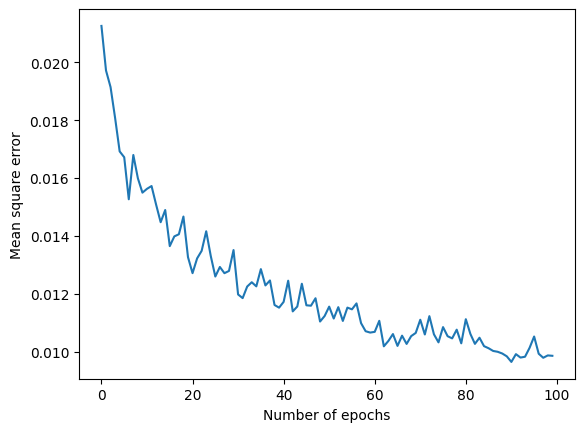

In [43]:
plt.plot(range(len(epoch_loss)) , epoch_loss)
plt.ylabel("Mean square error")
plt.xlabel("Number of epochs")
plt.show()


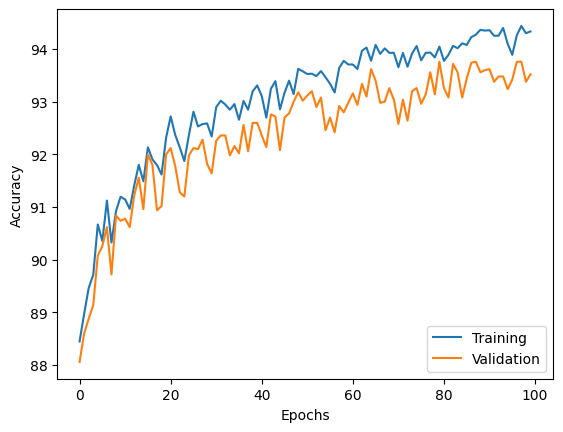

In [44]:
plt.plot(range(len(epoch_train_acc)), epoch_train_acc,
          label='Training')
plt.plot(range(len(epoch_valid_Acc)), epoch_valid_Acc,
          label='Validation')
plt.ylabel('Accuracy')
plt.xlabel('Epochs')
plt.legend(loc='lower right')
plt.show()


In [45]:
test_mse, test_acc = compute_mse_and_acc(model, X_test, y_test)
print(f'Test accuracy : {test_acc*100:.2f}%')

Test accuracy : 93.64%


C:\Users\muham\AppData\Local\Temp\ipykernel_12168\3184362591.py:4: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-z))


C:\Users\muham\AppData\Local\Temp\ipykernel_12168\3184362591.py:4: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-z))


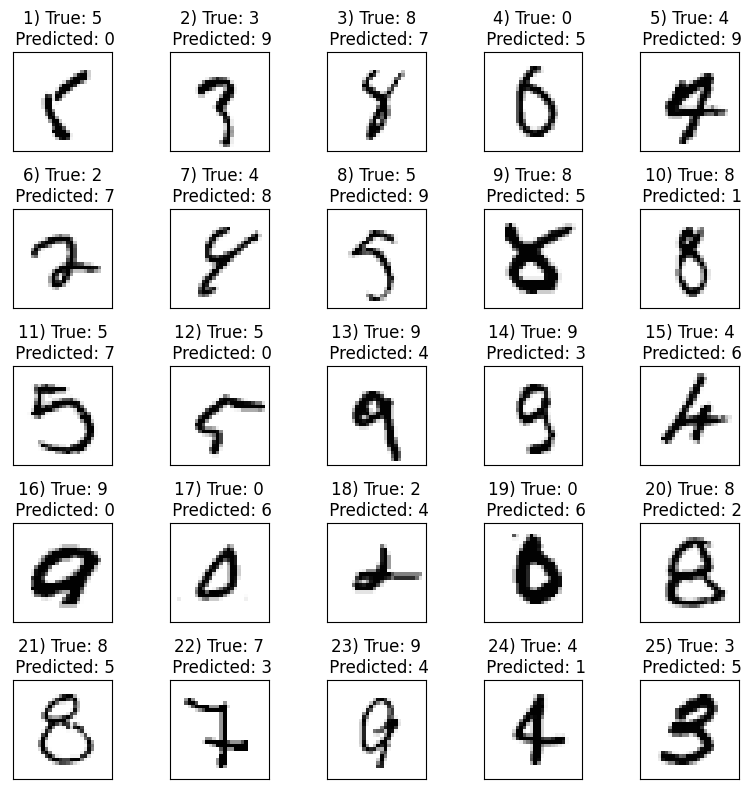

: 

In [ ]:
X_test_subset = X_test[:1000, :]
y_test_subset = y_test[:1000]
_,probas = model.forward(X_test_subset)
test_pred = np.argmax(probas, axis=1)
misclassified_images = X_test_subset[y_test_subset != test_pred][:25]
misclassified_labels = test_pred[y_test_subset != test_pred][:25]
correct_labels = y_test_subset[y_test_subset != test_pred][:25]

fig, ax = plt.subplots(nrows=5, ncols=5,
                       sharex=True, sharey=True,
                       figsize=(8, 8))
ax = ax.flatten()
for i in range(25):
    img = misclassified_images[i].reshape(28, 28)
    ax[i].imshow(img, cmap='Greys', interpolation='nearest')
    ax[i].set_title(f'{i+1}) '
                    f'True: {correct_labels[i]}\n'
                    f' Predicted: {misclassified_labels[i]}')

ax[0].set_xticks([])
ax[0].set_yticks([])
plt.tight_layout()
plt.show()

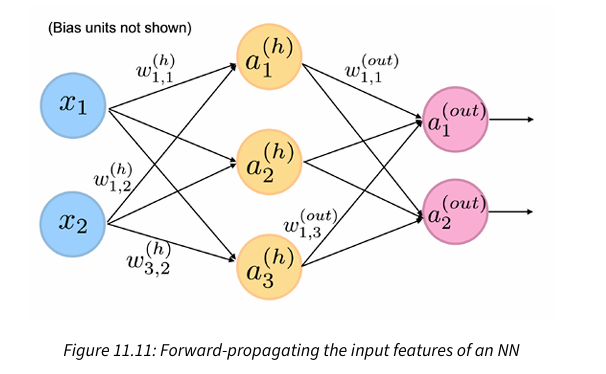